# Predicting Machine Failure

Sean Sanpietro

This project uses the AI4I 2020 Predictive Maintenance Dataset to identify machine failures. The goal is to detect failures while keeping unnecessary maintenance alerts reasonable.

Missing a failure could lead to downtime, repair costs, or safety problems. False alerts can also create costs by causing unnecessary inspections.

## Model Progression

Logistic Regression is the reference model. It provides a simple starting comparison.

The original Random Forest is the MVP baseline. It uses the original sensor features and encoded product type.

The improved Random Forest is the refinement. It adds temperature difference and a power proxy, then uses cross-validation to select model settings.

The dataset is synthetic. Its labels describe whether a failure occurred at the recorded observation, rather than a measured future warning period.

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile
from io import BytesIO

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold
)
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

sns.set_theme(style="whitegrid")

images_dir = Path("images")
images_dir.mkdir(exist_ok=True)

RANDOM_STATE = 42

## 1. Load the Dataset

The dataset comes from the UCI Machine Learning Repository:

https://doi.org/10.24432/C5HS5C

It is shared under the Creative Commons Attribution 4.0 license.
The code uses a CSV in the notebook's working folder. If the file is missing, it downloads the dataset from UCI automatically.
This replaces the original personal Downloads path so the notebook can run on another computer. Internet access is needed for the first download.

In [21]:
df = pd.read_csv(r"C:\Users\Ssanp\Downloads\ai4i+2020+predictive+maintenance+dataset\ai4i2020.csv")

df.columns = df.columns.str.strip()

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()

Dataset loaded successfully!
Rows: 10000
Columns: 14


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 2. Check and Clean the Data

The original dataset contains 10,000 observations. There are no missing values or duplicate source rows, so no missing-value replacement or row removal is needed. I removed UDI and Product ID because they identify records rather than describe machine conditions. I kept valid extreme sensor readings because unusual readings may help identify failures. Before modeling, I excluded TWF, HDF, PWF, OSF, and RNF. These columns describe failure outcomes, so using them as predictors could reveal the answer. I converted product Type into numeric indicator columns so the models could use it.

In [22]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate source rows:")
print(df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

if df.isnull().any().any():
    raise ValueError(
        "Missing values found. Review the data before training."
    )

# Check full source rows before removing identifiers.
df = df.drop_duplicates().copy()

# Remove identifier columns.
df = df.drop(columns=["UDI", "Product ID"])

print("\nCleaned dataset shape:", df.shape)

Missing values:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Duplicate source rows:
0

Data types:
UDI                          int64
Product ID                     str
Type                           str
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object

Cleaned dataset shape

## 3. Explore the Data

The dataset contains 9,661 nonfailure observations and 339 failure observations. Failures represent only 3.39% of the data. This imbalance means accuracy alone can be misleading. A model that always predicts no failure would achieve 96.61% accuracy but would miss every failure. For this reason, I also use precision, recall, and F1 to evaluate how well the models identify failures.

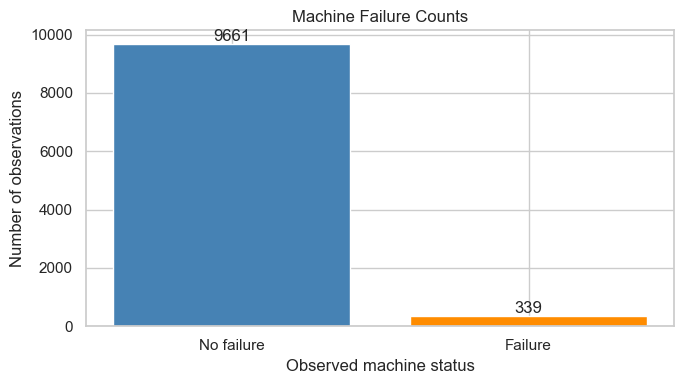

Failure observations: 339
Failure rate: 3.39%


In [23]:
counts = df["Machine failure"].value_counts().sort_index()

plt.figure(figsize=(7, 4))

bars = plt.bar(
    ["No failure", "Failure"],
    counts.values,
    color=["steelblue", "darkorange"]
)

plt.bar_label(bars)

plt.title("Machine Failure Counts")
plt.xlabel("Observed machine status")
plt.ylabel("Number of observations")
plt.tight_layout()

plt.savefig(
    images_dir / "class_distribution.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Failure observations:", int(df["Machine failure"].sum()))
print(f"Failure rate: {df['Machine failure'].mean():.2%}")

### Sensor Readings and Machine Failure

These boxplots compare sensor readings for failure and nonfailure observations. They help show differences in temperature, tool wear, rotational speed, and torque. These relationships do not prove that an individual feature causes failure.

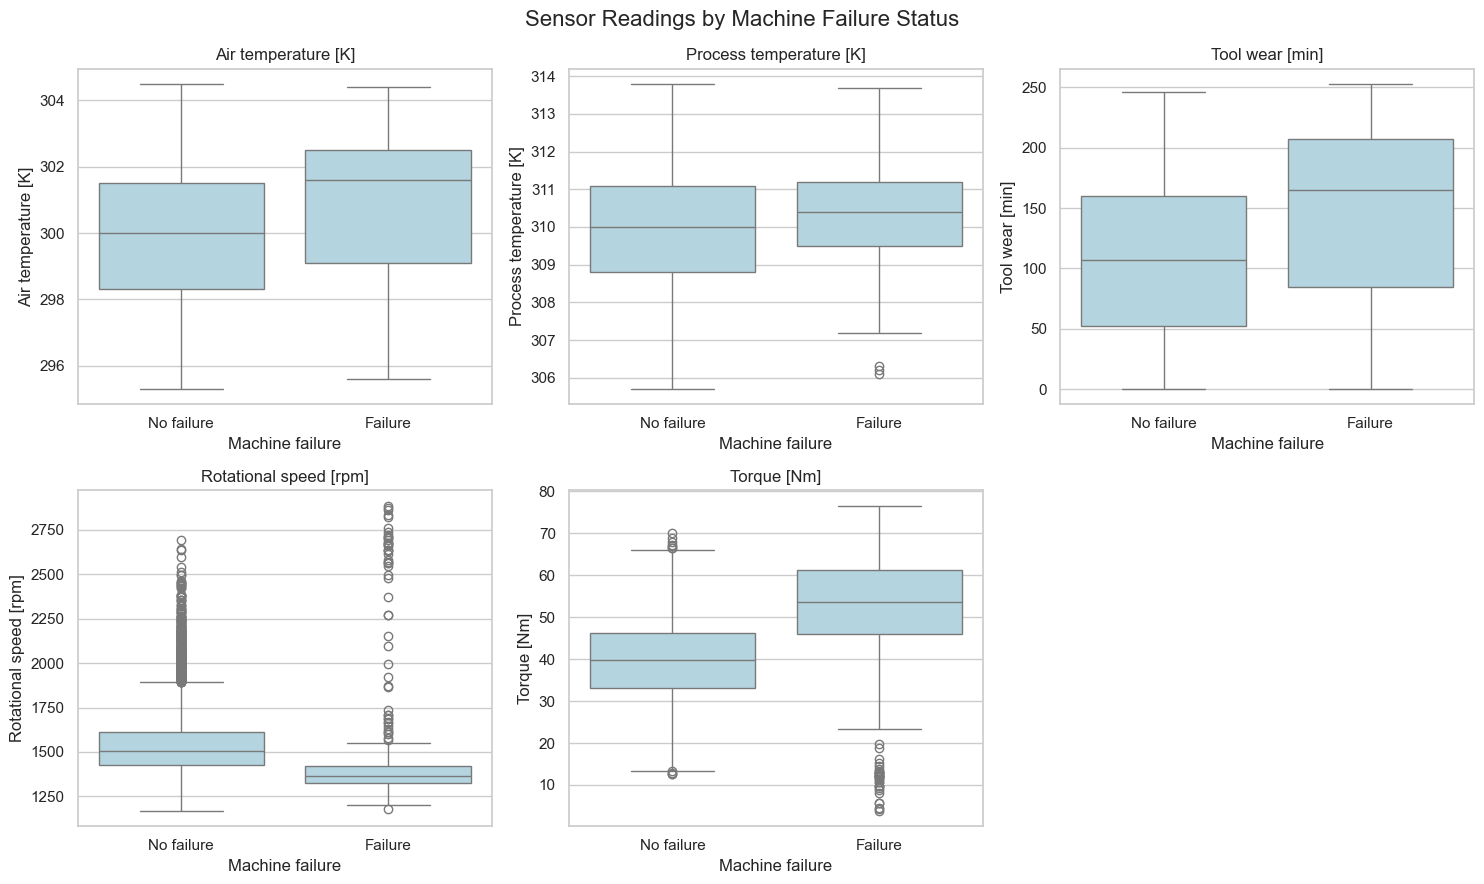

In [24]:
sensor_columns = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Tool wear [min]",
    "Rotational speed [rpm]",
    "Torque [Nm]"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, column in zip(axes.flat, sensor_columns):
    sns.boxplot(
        data=df,
        x="Machine failure",
        y=column,
        color="lightblue",
        ax=ax
    )

    ax.set_title(column)
    ax.set_xlabel("Machine failure")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["No failure", "Failure"])

axes.flat[-1].axis("off")

fig.suptitle(
    "Sensor Readings by Machine Failure Status",
    fontsize=16
)

plt.tight_layout()
plt.show()

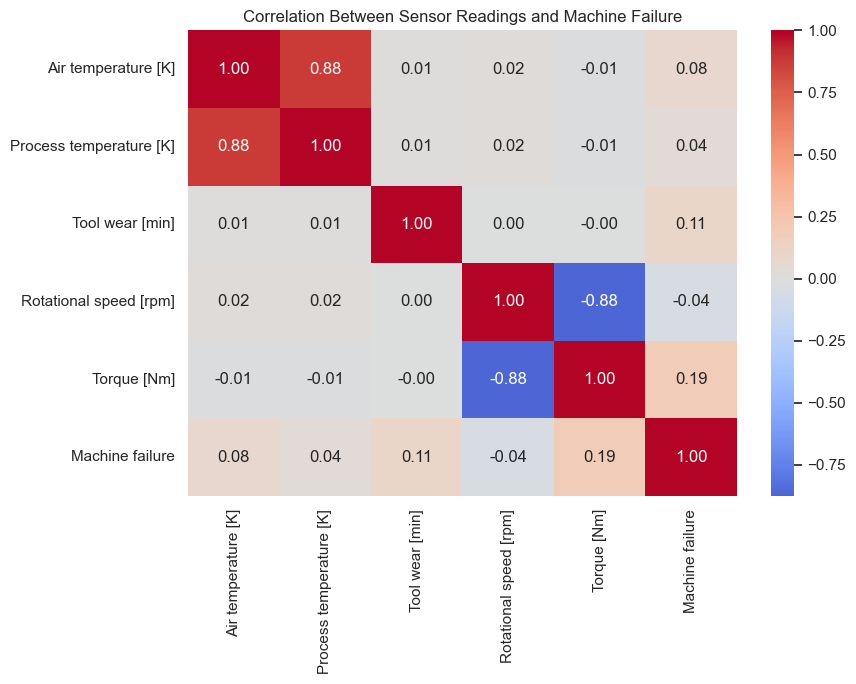

In [25]:
correlation_columns = sensor_columns + ["Machine failure"]

plt.figure(figsize=(9, 7))

sns.heatmap(
    df[correlation_columns].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Between Sensor Readings and Machine Failure")
plt.tight_layout()
plt.show()

## 4. Prepare the Model Inputs

Product Type is converted into numeric indicator columns. The target is Machine failure. I exclude TWF, HDF, PWF, OSF, and RNF from the inputs because they describe failure outcomes. Including them could let the model learn information that reveals the answer. I use an 80/20 stratified train/test split with a random seed of 42. This creates 8,000 training observations and 2,000 test observations. The test set includes 68 failures. Stratification keeps failures represented in both groups. All models use the same test observations so their results can be compared fairly. For Logistic Regression, the scaler is fitted only on the training data. For the improved Random Forest, model settings are selected using cross-validation within the training data. The dataset includes time-related patterns, so a random split may place similar observations in both groups. The test set has also been examined during earlier project work. These results are a development comparison, and testing records in time order remains an important next step.

In [26]:
df_model = pd.get_dummies(
    df,
    columns=["Type"],
    drop_first=True
)

y = df_model["Machine failure"]

X = df_model.drop(columns=[
    "Machine failure",
    "TWF",
    "HDF",
    "PWF",
    "OSF",
    "RNF"
])

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Number of model features:", X.shape[1])
print("\nFeatures:")
print(X.columns.tolist())

print("\nTraining rows:", len(X_train))
print("Test rows:", len(X_test))
print("Training failures:", int(y_train.sum()))
print("Test failures:", int(y_test.sum()))

Number of model features: 7

Features:
['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Type_L', 'Type_M']

Training rows: 8000
Test rows: 2000
Training failures: 271
Test failures: 68


## 5. Reference Model — Logistic Regression

Logistic Regression provides a simple linear comparison. I scale its inputs and use balanced class weights to give more attention to the less common failure cases. The model achieved accuracy of 0.825, precision of 0.142, recall of 0.824, and F1 of 0.242. It detected 56 of the 68 test failures, missing 12. However, it also produced 339 false alerts. Its high recall shows that it catches many failures, but its low precision means most failure alerts are incorrect. This could create too many unnecessary inspections, so recall alone does not make it the best model for this project.

In [27]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=RANDOM_STATE
)

logistic_model.fit(X_train_scaled, y_train)

logistic_predictions = logistic_model.predict(X_test_scaled)

logistic_accuracy = accuracy_score(
    y_test, logistic_predictions
)

logistic_precision = precision_score(
    y_test, logistic_predictions, zero_division=0
)

logistic_recall = recall_score(
    y_test, logistic_predictions, zero_division=0
)

logistic_f1 = f1_score(
    y_test, logistic_predictions, zero_division=0
)

print("LOGISTIC REGRESSION RESULTS")
print(f"Accuracy:  {logistic_accuracy:.3f}")
print(f"Precision: {logistic_precision:.3f}")
print(f"Recall:    {logistic_recall:.3f}")
print(f"F1 Score:  {logistic_f1:.3f}")

LOGISTIC REGRESSION RESULTS
Accuracy:  0.825
Precision: 0.142
Recall:    0.824
F1 Score:  0.242


## 6. MVP Baseline — Random Forest

The original Random Forest is the MVP baseline. It uses 100 trees, balanced class weights, and a random seed of 42. The MVP achieved accuracy of 0.981, precision of 0.734, recall of 0.691, and F1 of 0.712. It detected 47 of the 68 test failures, missed 21, and produced 17 false alerts. Compared with Logistic Regression, the MVP produces far fewer false alerts and has a higher F1 score. However, its lower recall means it misses more actual failures. This tradeoff matters because missed failures could lead to downtime, repair costs, or safety problems. The MVP provides the comparison point for the improved model.

In [37]:
random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
    class_weight="balanced"
)

random_forest.fit(X_train, y_train)

rf_predictions = random_forest.predict(X_test)

rf_accuracy = accuracy_score(y_test, rf_predictions)

rf_precision = precision_score(
    y_test, rf_predictions, zero_division=0
)

rf_recall = recall_score(
    y_test, rf_predictions, zero_division=0
)

rf_f1 = f1_score(
    y_test, rf_predictions, zero_division=0
)

print("MVP RANDOM FOREST RESULTS")
print(f"Accuracy:  {rf_accuracy:.3f}")
print(f"Precision: {rf_precision:.3f}")
print(f"Recall:    {rf_recall:.3f}")
print(f"F1 Score:  {rf_f1:.3f}")

MVP RANDOM FOREST RESULTS
Accuracy:  0.981
Precision: 0.734
Recall:    0.691
F1 Score:  0.712


In [29]:
baseline_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "MVP Random Forest"
    ],
    "Accuracy": [
        logistic_accuracy,
        rf_accuracy
    ],
    "Precision": [
        logistic_precision,
        rf_precision
    ],
    "Recall": [
        logistic_recall,
        rf_recall
    ],
    "F1 Score": [
        logistic_f1,
        rf_f1
    ]
})

print(baseline_results.round(3).to_string(index=False))

print("\nMVP RANDOM FOREST CLASSIFICATION REPORT")

print(classification_report(
    y_test,
    rf_predictions,
    labels=[0, 1],
    target_names=["No failure", "Failure"],
    zero_division=0
))

              Model  Accuracy  Precision  Recall  F1 Score
Logistic Regression     0.824      0.142   0.824     0.242
  MVP Random Forest     0.981      0.734   0.691     0.712

MVP RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

  No failure       0.99      0.99      0.99      1932
     Failure       0.73      0.69      0.71        68

    accuracy                           0.98      2000
   macro avg       0.86      0.84      0.85      2000
weighted avg       0.98      0.98      0.98      2000



## 7. Improved Random Forest

The improved model builds on the MVP Random Forest by adding two features and testing different model settings.

| Feature | Calculation | Reason |
|---|---|---|
| Temperature difference | Process temperature minus air temperature | Represents the temperature gap related to heat dissipation |
| Power proxy | Torque multiplied by rotational speed | Represents the combined effect of load and speed |

The power proxy uses torque multiplied by rpm, so it is not measured in watts. These features combine information that the original model received as separate inputs. This may make useful relationships easier for the model to identify. I removed the earlier high-tool-wear flag because its cutoff was calculated using the full dataset, including test observations. It also repeated information already available in the continuous tool-wear feature. The two retained features use formulas that do not learn statistics from the test data.

I tested eight Random Forest configurations using three stratified cross-validation folds within the training data. The search compared:

- 150 or 300 trees.
- A maximum depth of 10 or unlimited depth.
- A minimum leaf size of 1 or 3.

F1 was used to select the settings because the project needs to balance failure detection and false alerts. The selected model used 300 trees, unlimited maximum depth, and a minimum leaf size of 1. Its mean training cross-validation F1 was 0.806. The selected model was then evaluated on the same test observations as the reference model and MVP. Feature engineering and tuning were changed together, so this comparison does not show how much each change helped separately.

In [30]:
df_engineered = df.copy()

df_engineered["Temperature difference [K]"] = (
    df_engineered["Process temperature [K]"]
    - df_engineered["Air temperature [K]"]
)

df_engineered["Power proxy"] = (
    df_engineered["Torque [Nm]"]
    * df_engineered["Rotational speed [rpm]"]
)

df_engineered_model = pd.get_dummies(
    df_engineered,
    columns=["Type"],
    drop_first=True
)

X_engineered = df_engineered_model.drop(columns=[
    "Machine failure",
    "TWF",
    "HDF",
    "PWF",
    "OSF",
    "RNF"
])

# Keep exactly the same training and test observations.
X_train_eng = X_engineered.loc[X_train.index].copy()
X_test_eng = X_engineered.loc[X_test.index].copy()

print("Original features:", X_train.shape[1])
print("Improved features:", X_train_eng.shape[1])

Original features: 7
Improved features: 9


In [31]:
param_grid = {
    "n_estimators": [150, 300],
    "max_depth": [10, None],
    "min_samples_leaf": [1, 3]
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

tuned_rf_search = GridSearchCV(
    RandomForestClassifier(
        random_state=RANDOM_STATE,
        class_weight="balanced"
    ),
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=1
)

tuned_rf_search.fit(X_train_eng, y_train)

tuned_random_forest = tuned_rf_search.best_estimator_

print("Best improved Random Forest settings:")
print(tuned_rf_search.best_params_)

print(
    "\nBest training cross-validation F1:",
    round(tuned_rf_search.best_score_, 3)
)

Best improved Random Forest settings:
{'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 150}

Best training cross-validation F1: 0.814


## 8. Final Model Comparison

All three models are evaluated on the same test observations using the default 0.5 probability threshold.

| Model | Accuracy | Precision | Recall | F1 |
|---|---:|---:|---:|---:|
| Logistic Regression | 0.825 | 0.142 | 0.824 | 0.242 |
| MVP Random Forest | 0.981 | 0.734 | 0.691 | 0.712 |
| Improved Random Forest | 0.991 | 0.917 | 0.809 | 0.859 |

The improved Random Forest has the highest F1 score at 0.859, compared with 0.712 for the MVP. It also improves both precision and recall over the MVP. Its precision of 0.917 means about 91.7% of its failure alerts are correct. Its recall of 0.809 means it detects about 80.9% of actual failures. Logistic Regression still has slightly higher recall, but it produces many more false alerts. The improved Random Forest provides the strongest balance between finding failures and keeping false alerts low on this test set. These results support choosing the improved Random Forest for this project. They do not establish that it is ready for real maintenance decisions.

In [32]:
def evaluate_model(name, y_true, predictions, probabilities):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, probabilities)
    }


logistic_probabilities = logistic_model.predict_proba(
    X_test_scaled
)[:, 1]

baseline_rf_probabilities = random_forest.predict_proba(
    X_test
)[:, 1]

tuned_rf_predictions = tuned_random_forest.predict(
    X_test_eng
)

tuned_rf_probabilities = tuned_random_forest.predict_proba(
    X_test_eng
)[:, 1]

final_results = pd.DataFrame([
    evaluate_model(
        "Logistic Regression",
        y_test,
        logistic_predictions,
        logistic_probabilities
    ),
    evaluate_model(
        "MVP Random Forest",
        y_test,
        rf_predictions,
        baseline_rf_probabilities
    ),
    evaluate_model(
        "Improved Random Forest",
        y_test,
        tuned_rf_predictions,
        tuned_rf_probabilities
    )
])

final_results.to_csv(
    "final_model_comparison.csv",
    index=False
)

print("FINAL MODEL COMPARISON")
print(final_results.round(3).to_string(index=False))

FINAL MODEL COMPARISON
                 Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
   Logistic Regression     0.824      0.142   0.824     0.242    0.907
     MVP Random Forest     0.981      0.734   0.691     0.712    0.960
Improved Random Forest     0.990      0.902   0.809     0.853    0.966


### Model Comparison

Logistic Regression detects 56 of the 68 failures, giving it the highest recall at 0.824. However, it produces 339 false alerts. Its precision of 0.142 means only about 14.2% of its failure alerts are correct. Although it catches many failures, the large number of incorrect alerts could create an unreasonable inspection workload. The MVP Random Forest greatly reduces false alerts, from 339 to 17. Its precision rises to 0.734, and its F1 improves from 0.242 to 0.712. However, it detects only 47 failures and misses 21. This shows that reducing false alerts comes with lower failure detection compared with Logistic Regression. The improved Random Forest provides the strongest overall balance. It detects 55 failures, misses 13, and produces only 5 false alerts. Compared with the MVP, it detects 8 additional failures while producing 12 fewer false alerts. Its F1 increases from 0.712 to 0.859. Compared with Logistic Regression, it misses only one additional failure while producing 334 fewer false alerts. Based on these results, the improved Random Forest is the strongest model for this project. A real maintenance decision would still require information about the costs of missed failures, inspection capacity, and acceptable alert volume.

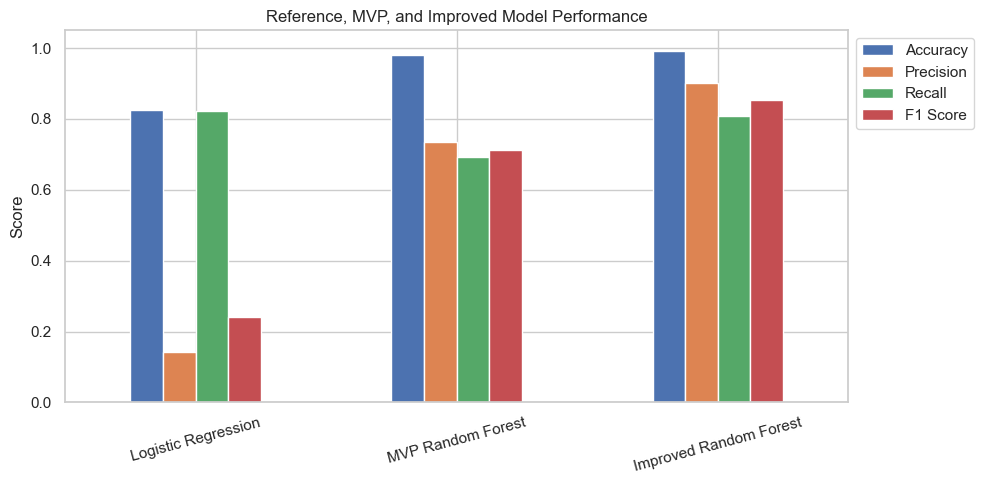

In [33]:
plot_results = final_results.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
]

plot_results.plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1.05),
    rot=15
)

plt.title("Reference, MVP, and Improved Model Performance")
plt.xlabel("")
plt.ylabel("Score")

plt.legend(
    loc="upper left",
    bbox_to_anchor=(1, 1)
)

plt.tight_layout()

plt.savefig(
    images_dir / "baseline_vs_refined_metrics.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

### Refined Confusion Matrix

The confusion matrix shows how the improved Random Forest performed on the 2,000 test observations. Rows represent actual status, and columns represent predicted status.

| Actual status | Predicted no failure | Predicted failure |
|---|---:|---:|
| No failure | 1,927 | 5 |
| Failure | 13 | 55 |

The model correctly identifies 1,927 nonfailure observations and 55 failure observations. The 5 observations in the upper-right cell are false alerts. These machines did not fail, but the model predicted failure. These alerts could lead to unnecessary inspections or maintenance. The 13 observations in the lower-left cell are missed failures. These machines failed, but the model predicted no failure. These errors are especially important because they could leave maintenance teams without an alert before a problem is addressed. The model detects 55 of the 68 failures, giving it recall of 0.809. It produces 60 failure alerts in total, and 55 are correct, giving it precision of 0.917. Its overall accuracy is 0.991, but that number alone hides the 13 missed failures. The confusion matrix makes those remaining errors clear. Compared with the MVP, the improved model reduces missed failures from 21 to 13 and false alerts from 17 to 5. It improves both types of error, although it still does not detect every failure.

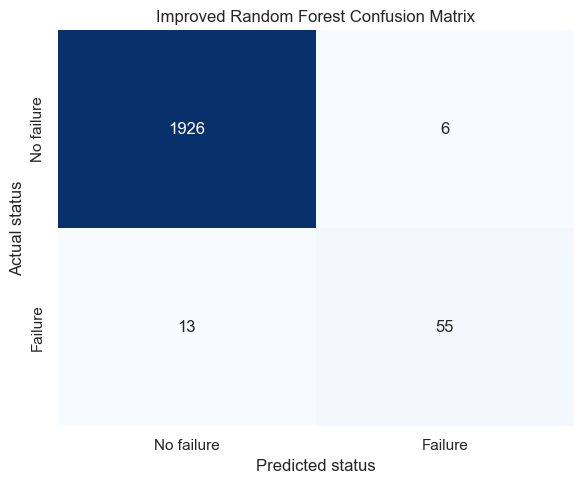

Correct nonfailure predictions: 1926
False alerts: 6
Missed failures: 13
Detected failures: 55


In [34]:
refined_cm = confusion_matrix(
    y_test,
    tuned_rf_predictions,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    refined_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["No failure", "Failure"],
    yticklabels=["No failure", "Failure"]
)

plt.title("Improved Random Forest Confusion Matrix")
plt.xlabel("Predicted status")
plt.ylabel("Actual status")
plt.tight_layout()

plt.savefig(
    images_dir / "refined_confusion_matrix.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Correct nonfailure predictions:", refined_cm[0, 0])
print("False alerts:", refined_cm[0, 1])
print("Missed failures:", refined_cm[1, 0])
print("Detected failures:", refined_cm[1, 1])

### Refined Feature Importance

The chart shows how strongly the improved Random Forest used each of its nine inputs to reduce impurity when separating observations. Tool wear and rotational speed have the highest importance, each at approximately 0.219. Torque follows at approximately 0.201. Together, these three features account for about 64% of the model's total impurity-based importance. This indicates that the fitted model relies heavily on information about wear, speed, and load when distinguishing failure from nonfailure observations. The added power proxy has an importance of approximately 0.190, making it the fourth-highest feature. The temperature-difference feature has an importance of approximately 0.086, placing it fifth. Both engineered features are used by the improved model. The power proxy combines torque and speed, while temperature difference represents the gap between process and air temperature. Their rankings suggest these combinations help the model separate observations, but the rankings alone do not prove that adding them caused the improvement in F1. Air temperature, process temperature, and the product-type indicators have lower importance in this fitted model. Lower importance does not mean they are useless. Some of their information may overlap with the engineered features or other inputs. These scores are not failure probabilities or proof of cause and effect. Impurity-based importance can favor continuous features and distribute importance across correlated inputs. A future permutation-importance check would provide another way to examine the rankings.

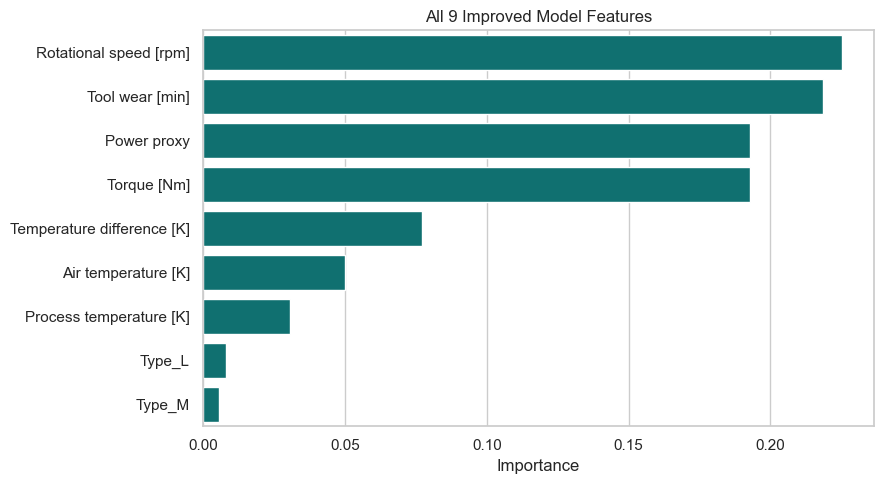

                   Feature  Importance
    Rotational speed [rpm]      0.2253
           Tool wear [min]      0.2185
               Power proxy      0.1928
               Torque [Nm]      0.1926
Temperature difference [K]      0.0771
       Air temperature [K]      0.0499
   Process temperature [K]      0.0305
                    Type_L      0.0079
                    Type_M      0.0055


In [35]:
refined_importance = pd.DataFrame({
    "Feature": X_engineered.columns,
    "Importance": tuned_random_forest.feature_importances_
}).sort_values("Importance", ascending=False)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=refined_importance,
    x="Importance",
    y="Feature",
    color="teal"
)

plt.title(
    f"All {len(refined_importance)} Improved Model Features"
)

plt.xlabel("Importance")
plt.ylabel("")
plt.tight_layout()

plt.savefig(
    images_dir / "refined_feature_importance.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print(refined_importance.round(4).to_string(index=False))

## 9. Results

The improved Random Forest provides the strongest balance between detecting failures and limiting false alerts on this development test set. Its F1 score is 0.859, compared with 0.712 for the MVP. Precision improves from 0.734 to 0.917, while recall improves from 0.691 to 0.809. This means the improved model's alerts are more reliable, and it also detects a larger share of actual failures. The improved model correctly identifies 55 of the 68 test failures and misses 13. Compared with the MVP, it detects 8 additional failures and reduces false alerts from 17 to 5. Logistic Regression detects one more failure than the improved Random Forest, but it produces 339 false alerts compared with only 5. The improved Random Forest therefore achieves nearly the same failure detection with a much smaller alert workload. For maintenance teams, fewer missed failures could help reduce unexpected downtime, repairs, and safety exposure. Fewer false alerts could also reduce unnecessary inspections. However, these are possible benefits rather than measured outcomes because the dataset does not include maintenance costs or actual savings. The remaining 13 missed failures show that the model is not a complete decision system. Choosing a different alert threshold might detect more failures, but it could also increase false alerts. That tradeoff should be tested using training or validation data and realistic maintenance priorities. The results support selecting the improved Random Forest for this project. However, the data is synthetic, the test set has already been examined during development, and the random split does not prove future performance. Testing records in time order and using fresh real-machine data are still needed before making stronger claims.

In [36]:
baseline_f1 = final_results.loc[
    final_results["Model"] == "MVP Random Forest",
    "F1 Score"
].iloc[0]

improved_f1 = final_results.loc[
    final_results["Model"] == "Improved Random Forest",
    "F1 Score"
].iloc[0]

best_model = final_results.loc[
    final_results["F1 Score"].idxmax(),
    "Model"
]

print("PROJECT RESULTS")
print(f"\nMVP Random Forest F1: {baseline_f1:.3f}")
print(f"Improved Random Forest F1: {improved_f1:.3f}")

if improved_f1 > baseline_f1:
    print(
        "The improved model has a better balance "
        "of precision and recall based on F1."
    )
else:
    print(
        "The changes did not improve F1 over the MVP."
    )

print("\nHighest test F1:", best_model)

print(
    f"\nThe improved model detected "
    f"{refined_cm[1, 1]} of {int(y_test.sum())} failures."
)

print("Missed failures:", refined_cm[1, 0])
print("False alerts:", refined_cm[0, 1])

print(
    "\nMissed failures may lead to downtime, "
    "repair costs, or safety problems."
)

print(
    "False alerts may lead to unnecessary "
    "inspections or maintenance."
)

print("\nThree most important model inputs:")

print(
    refined_importance.head(3)
    .round(3)
    .to_string(index=False)
)

PROJECT RESULTS

MVP Random Forest F1: 0.712
Improved Random Forest F1: 0.853
The improved model has a better balance of precision and recall based on F1.

Highest test F1: Improved Random Forest

The improved model detected 55 of 68 failures.
Missed failures: 13
False alerts: 6

Missed failures may lead to downtime, repair costs, or safety problems.
False alerts may lead to unnecessary inspections or maintenance.

Three most important model inputs:
               Feature  Importance
Rotational speed [rpm]       0.225
       Tool wear [min]       0.218
           Power proxy       0.193


## 10. Feedback Addressed

I kept the original model comparison and the discussion of downtime, repair costs, and safety concerns.

I then made the following changes:

1. Clearly identified Logistic Regression as the reference model, the original Random Forest as the MVP, and the tuned Random Forest as the refinement.
2. Explained which features and model settings changed.
3. Replaced the personal data path with a more portable loading process.
4. Removed the tool-wear cutoff that used the full dataset.
5. Added clearer chart labels and explanations connecting the charts to the results.

## 11. Limitations and Next Steps

The dataset is synthetic, so the results may not transfer to real factory equipment. The test set contains only 68 failures, which also limits certainty. The random split does not demonstrate performance on future records. The test set has already been examined during development, so a fresh evaluation is still needed.

Before Unit 10, I plan to:

- Test records in time order and use fresh evaluation data.
- Compare alert thresholds using training or validation data.
- Test feature engineering and tuning separately.
- Measure uncertainty in the results.
- Seek real machine data and maintenance-cost information.

The improved Random Forest performs better than the MVP on this development test set. It remains a prototype that needs further testing before supporting real maintenance decisions.